In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
from __future__ import annotations
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime
from typing import Any
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [3]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [4]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [5]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [6]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera',
  'ip_address': nan,
 

In [7]:
FEATURE_COLUMNS = [
    "packet_count",
    "total_bytes",
]

DEVICE_COLUMN = "eth.src"          # Replace with "eth.src" if applicable
TIME_COLUMN = "timestamp"
LABEL_COLUMN = "is_iot_device"

N_SPLITS = 5
N_VOTING_WINDOWS = 11
MINIMUM_PACKET_COUNT = 1
MAX_TRAIN_WINDOWS_PER_DEVICE = 40_000
RANDOM_STATE = 42
WINDOW_SECONDS = 4

In [8]:
def calculate_features(
    file_paths: Iterable[str],
    window: float,
) -> Tuple[pd.DataFrame, float]:
    if window <= 0:
        raise ValueError("window must be greater than 0.")

    columns = [
        "frame.time_epoch",
        "frame.len",
        "eth.src",
    ]

    all_features = []
    start_time = time.perf_counter()

    for file_path in file_paths:
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
            },
        )

        if df.empty:
            continue

        capture_start = df["frame.time_epoch"].min()

        df["window"] = (
            (df["frame.time_epoch"] - capture_start) // window
        ).astype("int32")

        basic_features = (
            df.groupby(
                ["window", "eth.src"],
                sort=False,
                observed=True,
            )
            .agg(
                packet_count=("frame.len", "size"),
                total_bytes=("frame.len", "sum"),

                # Timestamp of the first packet from this device
                # within this window.
                timestamp=("frame.time_epoch", "min"),
            )
            .reset_index()
        )

        # Retain which input capture produced each feature row.
        basic_features["capture_id"] = Path(file_path).stem

        all_features.append(basic_features)

    elapsed_time = time.perf_counter() - start_time

    if not all_features:
        empty_result = pd.DataFrame(
            columns=[
                "capture_id",
                "window",
                "timestamp",
                "eth.src",
                "packet_count",
                "total_bytes",
            ]
        )
        return empty_result, elapsed_time

    result = pd.concat(
        all_features,
        ignore_index=True,
    )

    result["packet_count"] = result["packet_count"].astype("int32")
    result["total_bytes"] = result["total_bytes"].astype("int64")

    result = result.sort_values(
        ["timestamp", "eth.src"],
        ignore_index=True,
    )

    return result, elapsed_time

In [9]:
def label_features(features: pd.DataFrame, device_mapping: Dict[str, Dict[str, str]]) -> pd.DataFrame:
    # Check if eth.src is in device_mapping, and get label is_iot_device, device_type, and vendor
    features["is_iot_device"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("is_iot_device", 0)
    )
    features["device_type"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("device_type", "unknown")
    )
    features["vendor"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("vendor", "unknown")
    )
    return features
    

In [10]:
features1, _ = calculate_features(csv_files_1, window=WINDOW_SECONDS)
features1 = label_features(features1, device_dict_1)

In [11]:
features1.head(10)

,window,eth.src,packet_count,total_bytes,timestamp,capture_id,is_iot_device,device_type,vendor
0,0,18:b7:9e:02:20:44,3,202,1.474553e+09,16-09-23,1,smart speaker,Invoxia
1,0,14:cc:20:51:33:ea,18,1449,1.474553e+09,16-09-23,0,unknown,unknown
2,0,d0:52:a8:00:67:5e,3,259,1.474553e+09,16-09-23,1,hub,Samsung SmartThings
3,0,70:ee:50:18:34:43,3,284,1.474553e+09,16-09-23,1,camera,Netatmo
4,0,ec:1a:59:79:f4:89,1,42,1.474553e+09,16-09-23,1,smart switch,Belkin
5,0,30:8c:fb:2f:e4:b2,4,624,1.474553e+09,16-09-23,1,camera,Dropcam
6,0,00:24:e4:11:18:a8,2,132,1.474553e+09,16-09-23,1,baby monitor,Withings
7,1,08:21:ef:3b:fc:e3,2,108,1.474553e+09,16-09-23,0,unknown,unknown
8,1,14:cc:20:51:33:ea,7,495,1.474553e+09,16-09-23,0,unknown,unknown
9,1,f4:f2:6d:93:51:f1,2,214,1.474553e+09,16-09-23,1,camera,TP-Link


In [12]:
counts = features1.groupby(["eth.src", "is_iot_device"]).size().reset_index(name="count")
counts.sort_values(by="is_iot_device", ascending=False, inplace=True)
counts

,eth.src,is_iot_device,count
0,00:16:6c:ab:6b:88,1,186414
13,44:65:0d:56:cc:d3,1,209131
31,ec:1a:59:83:28:11,1,108373
30,ec:1a:59:79:f4:89,1,105078
29,e8:ab:fa:19:de:4f,1,91
28,e0:76:d0:33:bb:85,1,15070
25,d0:73:d5:01:83:08,1,53583
24,d0:52:a8:00:67:5e,1,221632
20,74:c6:3b:29:d7:1d,1,23468
19,74:6a:89:00:2e:25,1,15


In [13]:
features1[features1["eth.src"] == "18:b7:9e:02:20:44"]["capture_id"].unique()

<ArrowStringArray>
['16-09-23', '16-09-24', '16-09-25', '16-09-26', '16-09-27', '16-09-28',
 '16-09-29', '16-09-30', '16-10-01', '16-10-02', '16-10-03', '16-10-04',
 '16-10-05', '16-10-06', '16-10-07', '16-10-08', '16-10-09', '16-10-10',
 '16-10-11', '16-10-12']
Length: 20, dtype: str

In [14]:
def generate_stratified_group_splits(
    df: pd.DataFrame,
    n_splits: int = 5,
    random_state: int = 42,
):
    """
    Stratify by `is_iot_device` while keeping every
    (`eth.src`, `capture_id`) group entirely within one split.
    """
    groups = (
        df["eth.src"].astype(str)
        + "__"
        + df["capture_id"].astype(str)
    )

    splitter = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    for train_idx, val_idx in splitter.split(
        X=df,
        y=df["is_iot_device"],
        groups=groups,
    ):
        yield train_idx, val_idx

In [15]:
import pandas as pd


def examine_folds(df: pd.DataFrame, splits):
    fold_results = []
    eth_src_results = []

    group_columns = ["eth.src", "capture_id"]

    for fold, (train_idx, val_idx) in enumerate(splits, start=1):
        train_df = df.iloc[train_idx]
        val_df = df.iloc[val_idx]

        train_groups = set(
            train_df[group_columns]
            .itertuples(index=False, name=None)
        )
        val_groups = set(
            val_df[group_columns]
            .itertuples(index=False, name=None)
        )

        overlapping_groups = train_groups & val_groups

        assert not overlapping_groups, (
            f"Data leakage detected in fold {fold}: "
            f"{len(overlapping_groups)} groups appear in both splits."
        )

        for split_name, split_df in [
            ("train", train_df),
            ("validation", val_df),
        ]:
            label_counts = (
                split_df["is_iot_device"]
                .value_counts()
                .reindex([0, 1], fill_value=0)
            )

            fold_results.append(
                {
                    "fold": fold,
                    "split": split_name,
                    "total_samples": len(split_df),
                    "non_iot_count": label_counts[0],
                    "iot_count": label_counts[1],
                    "non_iot_ratio": label_counts[0] / len(split_df),
                    "iot_ratio": label_counts[1] / len(split_df),
                    "unique_eth_src": split_df["eth.src"].nunique(),
                    "unique_groups": (
                        split_df[group_columns]
                        .drop_duplicates()
                        .shape[0]
                    ),
                    "overlapping_groups": len(overlapping_groups),
                }
            )

            eth_src_counts = (
                split_df
                .groupby(
                    ["eth.src", "is_iot_device"],
                    observed=True,
                )
                .agg(
                    sample_count=("eth.src", "size"),
                    capture_count=("capture_id", "nunique"),
                )
                .reset_index()
            )

            eth_src_counts.insert(0, "split", split_name)
            eth_src_counts.insert(0, "fold", fold)

            eth_src_results.append(eth_src_counts)

    fold_summary = pd.DataFrame(fold_results)

    eth_src_summary = pd.concat(
        eth_src_results,
        ignore_index=True,
    )

    return fold_summary, eth_src_summary

In [16]:
splits = list(
    generate_stratified_group_splits(
        features1,
        n_splits=5,
        random_state=42,
    )
)

fold_summary, eth_src_summary = examine_folds(
    features1,
    splits,
)

In [17]:
fold_summary

,fold,split,total_samples,non_iot_count,iot_count,non_iot_ratio,iot_ratio,unique_eth_src,unique_groups,overlapping_groups
0,1,train,2201102,399182,1801920,0.181356,0.818644,33,337,0
1,1,validation,550267,99785,450482,0.181339,0.818661,25,83,0
2,2,train,2201096,399176,1801920,0.181353,0.818647,33,333,0
3,2,validation,550273,99791,450482,0.181348,0.818652,27,87,0
4,3,train,2201072,399149,1801923,0.181343,0.818657,33,337,0
5,3,validation,550297,99818,450479,0.181389,0.818611,26,83,0
6,4,train,2201104,399181,1801923,0.181355,0.818645,33,336,0
7,4,validation,550265,99786,450479,0.181342,0.818658,25,84,0
8,5,train,2201102,399180,1801922,0.181355,0.818645,32,337,0
9,5,validation,550267,99787,450480,0.181343,0.818657,26,83,0


In [18]:
eth_src_summary.sort_values(by=["eth.src", "fold", "split"], inplace=True)
eth_src_summary.head(10)

,fold,split,eth.src,is_iot_device,sample_count,capture_count
0,1,train,00:16:6c:ab:6b:88,1,158858,17
33,1,validation,00:16:6c:ab:6b:88,1,27556,3
58,2,train,00:16:6c:ab:6b:88,1,156704,17
91,2,validation,00:16:6c:ab:6b:88,1,29710,3
118,3,train,00:16:6c:ab:6b:88,1,129432,14
151,3,validation,00:16:6c:ab:6b:88,1,56982,6
177,4,train,00:16:6c:ab:6b:88,1,151502,16
210,4,validation,00:16:6c:ab:6b:88,1,34912,4
235,5,train,00:16:6c:ab:6b:88,1,149160,16
267,5,validation,00:16:6c:ab:6b:88,1,37254,4


In [19]:
def create_under_sampler(random_seed: int = 42) -> RandomUnderSampler:
    """
    Create a RandomUnderSampler for undersampling the majority class.

    Args:
        random_seed (int): Random seed for reproducibility.

    Returns:
        RandomUnderSampler: An instance of the RandomUnderSampler.
    """
    return RandomUnderSampler(random_state=random_seed)

def create_decision_tree(random_seed: int = 42) -> DecisionTreeClassifier:
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight=None,
        random_state=random_seed,
    )

In [20]:
def custom_evaluation(y_pred: pd.DataFrame, y_true: pd.DataFrame, X_val: pd.DataFrame, labels: NDArray) -> Dict[str, float]:
    precisions = precision_score(y_true=y_true, y_pred=y_pred, labels=labels, average=None)
    recalls = recall_score(y_true=y_true, y_pred=y_pred, labels=labels, average=None)
    f1_scores = f1_score(y_true=y_true, y_pred=y_pred, labels=labels, average=None)
    accuracy = accuracy_score(y_true=y_true, y_pred=y_pred)

    metric_dict = {"accuracy": accuracy}
    for index, label in enumerate(labels):
        metric_dict[f"precision_class_{label}"] = precisions[index]
        metric_dict[f"recall_class_{label}"] = recalls[index]
        metric_dict[f"f1_class_{label}"] = f1_scores[index]

    y_true_array = np.asarray(y_true)
    y_pred_array = np.asarray(y_pred)

    false_positive_positions = np.flatnonzero(
        (y_true_array == 0) & (y_pred_array == 1)
    )

    false_negative_positions = np.flatnonzero(
        (y_true_array == 1) & (y_pred_array == 0)
    )

    false_positive_samples = X_val.iloc[false_positive_positions]
    false_negative_samples = X_val.iloc[false_negative_positions]

    fp_dict = (
        false_positive_samples
        .groupby(["eth.src", "device_type"], observed=True)
        .size()
        .to_dict()
    )

    fn_dict = (
        false_negative_samples
        .groupby(["eth.src", "device_type"], observed=True)
        .size()
        .to_dict()
    )

    metric_dict["false_positives"] = fp_dict
    metric_dict["false_negatives"] = fn_dict
        
    return metric_dict

In [ ]:
metrics = []
for fold, (train_idx, val_idx) in enumerate(splits, start=1):
    print(f"Fold {fold}: Training on {len(train_idx)} samples, validating on {len(val_idx)} samples.")
    train_df = features1.iloc[train_idx]
    val_df = features1.iloc[val_idx]

    X_train = train_df[FEATURE_COLUMNS]
    y_train = train_df[LABEL_COLUMN]
    X_val = val_df[FEATURE_COLUMNS]
    y_val = val_df[LABEL_COLUMN]

    sampler = create_under_sampler(random_seed=RANDOM_STATE)
    X_train_resampled, y_train_resampled = sampler.fit_resample(X_train, y_train)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_resampled)
    X_val_scaled = scaler.transform(X_val)

    model = create_decision_tree(random_seed=RANDOM_STATE)
    model.fit(X_train_scaled, y_train_resampled)

    y_pred = model.predict(X_val_scaled)
    metric_dict = custom_evaluation(y_pred, y_val, val_df, np.unique(y_val))
    metric_dict["iteration"] = fold
    metrics.append(metric_dict)



NameError: name 'splits' is not defined

In [22]:
metrics_df = pd.DataFrame(metrics)
metrics_df

,accuracy,precision_class_0,recall_class_0,f1_class_0,precision_class_1,recall_class_1,f1_class_1,false_positives,false_negatives,iteration
0,0.959865,0.848168,0.948459,0.895514,0.988276,0.962391,0.975162,"{('00:24:e4:10:ee:4c', 'unknown'): 185, ('08:2...","{('00:16:6c:ab:6b:88', 'camera'): 625, ('00:24...",1
1,0.969030,0.893193,0.941848,0.916876,0.986961,0.975051,0.980970,"{('08:21:ef:3b:fc:e3', 'unknown'): 3634, ('14:...","{('00:16:6c:ab:6b:88', 'camera'): 1761, ('00:2...",2
2,0.971583,0.896126,0.953906,0.924114,0.989638,0.975499,0.982518,"{('08:21:ef:3b:fc:e3', 'unknown'): 2298, ('14:...","{('00:16:6c:ab:6b:88', 'camera'): 2302, ('00:2...",3
3,0.969088,0.896718,0.937516,0.916663,0.986018,0.976081,0.981024,"{('08:21:ef:3b:fc:e3', 'unknown'): 4207, ('14:...","{('00:16:6c:ab:6b:88', 'camera'): 1248, ('00:2...",4
4,0.967230,0.892001,0.932155,0.911636,0.984820,0.975000,0.979886,"{('08:21:ef:3b:fc:e3', 'unknown'): 5624, ('14:...","{('00:16:6c:ab:6b:88', 'camera'): 879, ('00:24...",5


In [23]:
def plot_errors_by_iteration(metric_df: pd.DataFrame) -> None:
    for _, row in metric_df.iterrows():
        iteration = row["iteration"]

        for column, title in [
            ("false_positives", "False Positives"),
            ("false_negatives", "False Negatives"),
        ]:
            error_dict = row[column]

            plot_df = pd.DataFrame(
                [
                    {
                        "category": f"{eth_src}\n{device_type}",
                        "count": count,
                    }
                    for (eth_src, device_type), count in error_dict.items()
                ]
            ).sort_values("count", ascending=False)

            ax = plot_df.plot(
                x="category",
                y="count",
                kind="bar",
                figsize=(14, 6),
                legend=False,
            )

            ax.set_title(f"{title} — Iteration {iteration}")
            ax.set_xlabel("(eth.src, device_type)")
            ax.set_ylabel("Count")
            ax.tick_params(axis="x", rotation=45)

            plt.tight_layout()
            plt.show()

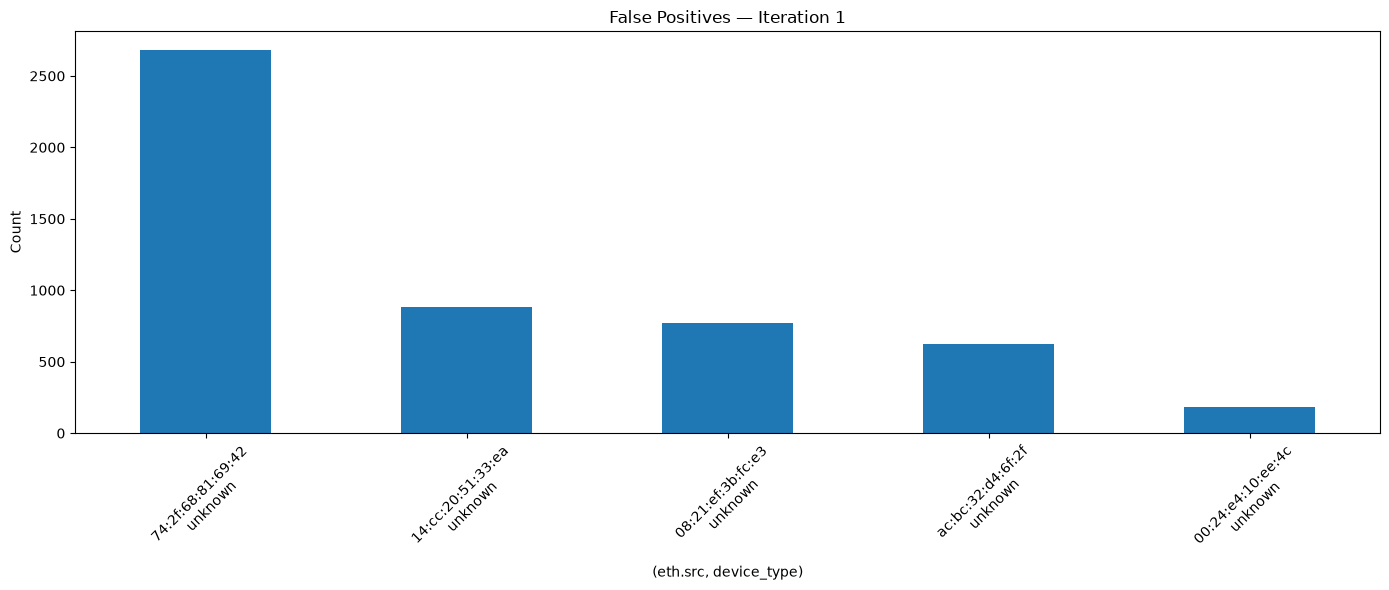

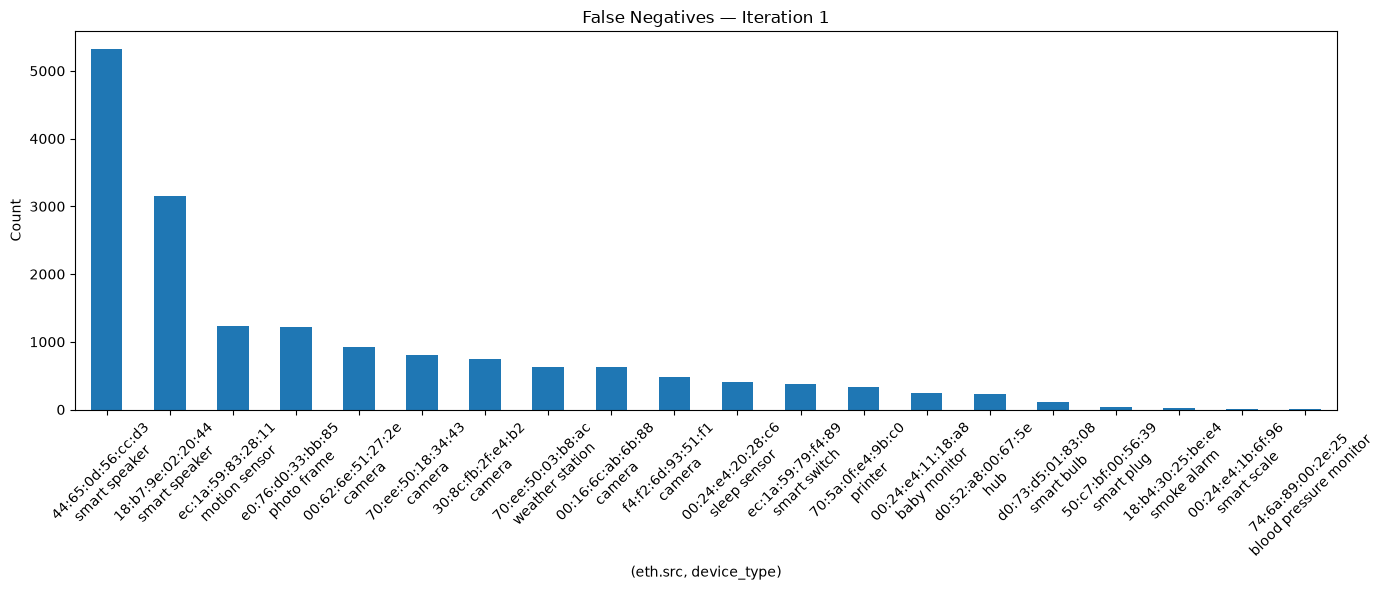

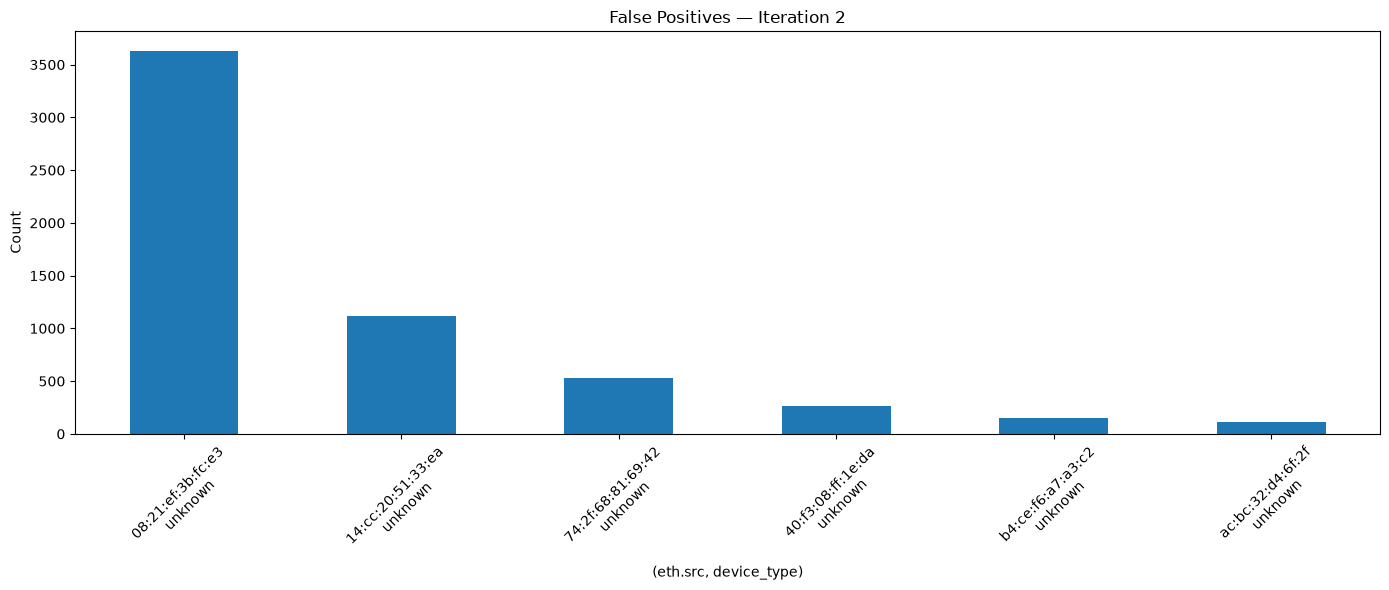

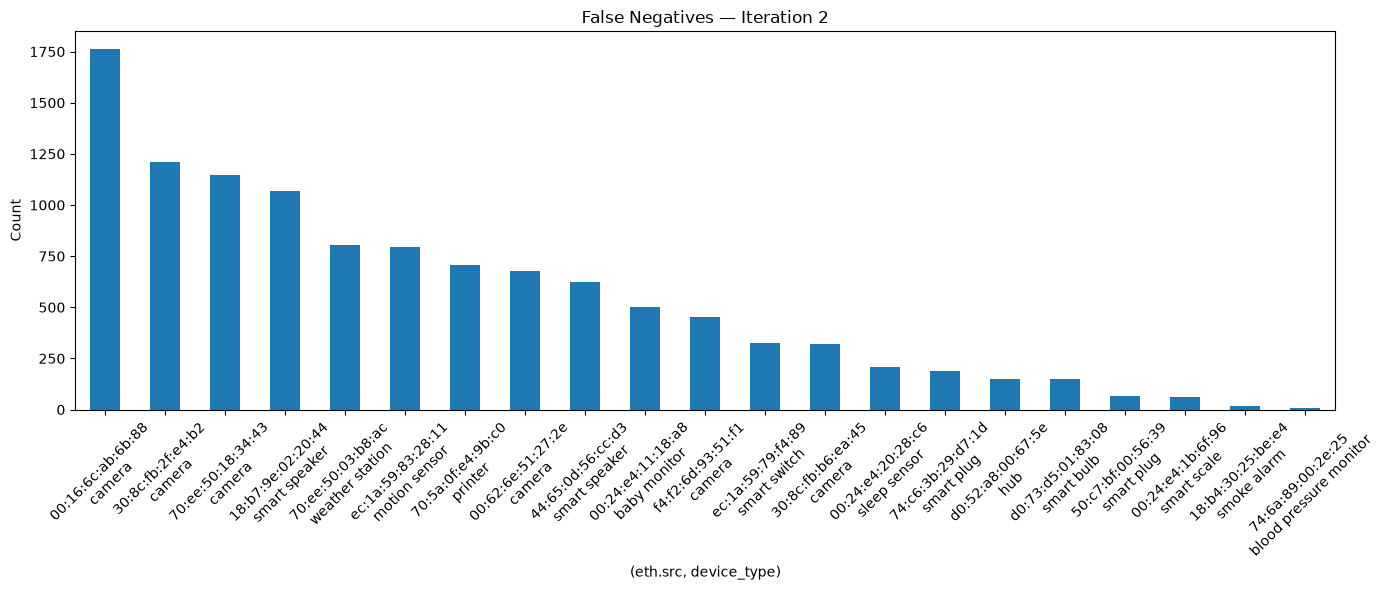

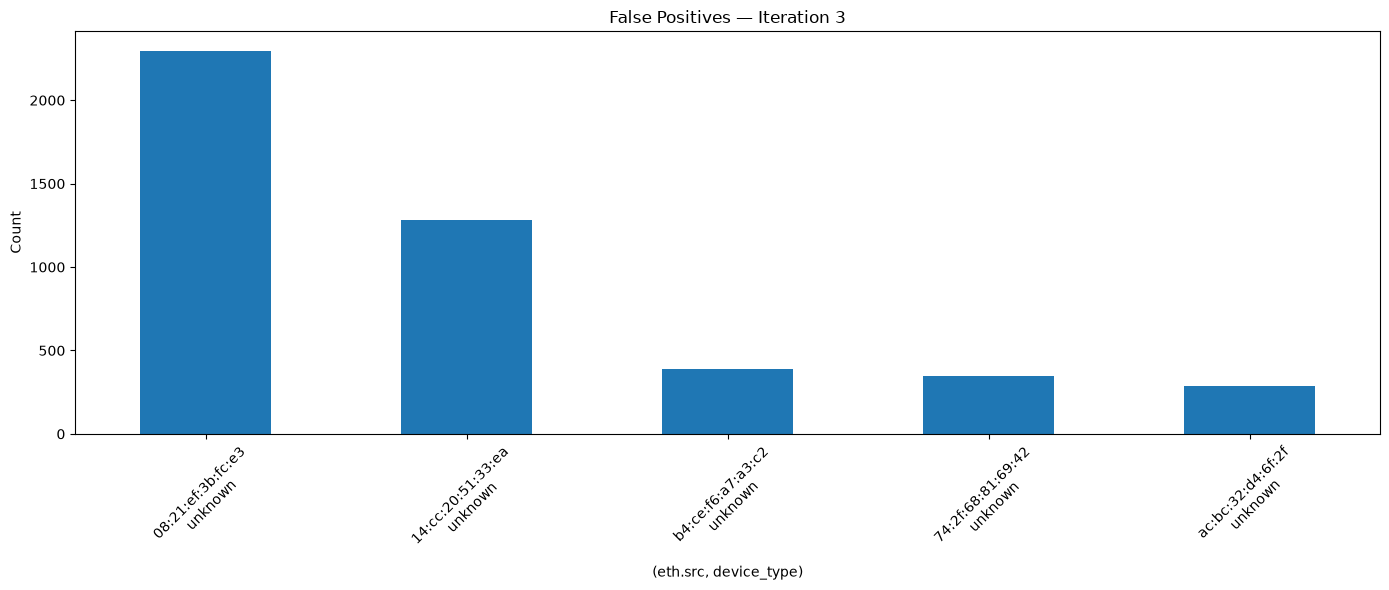

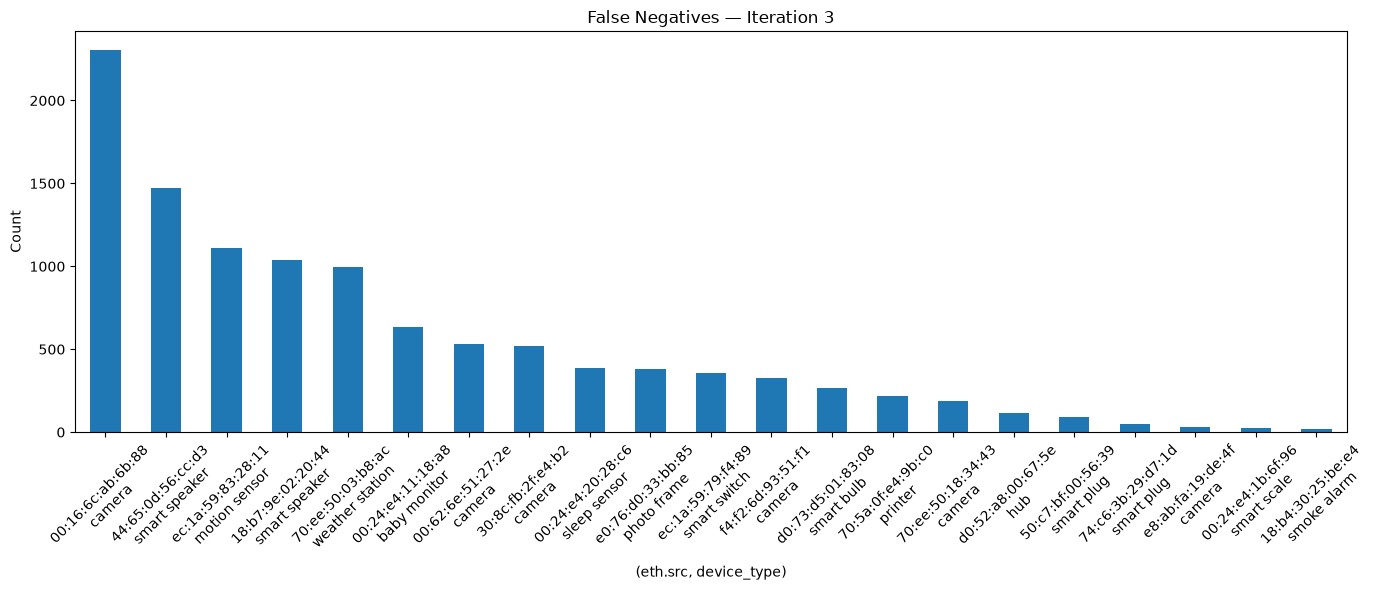

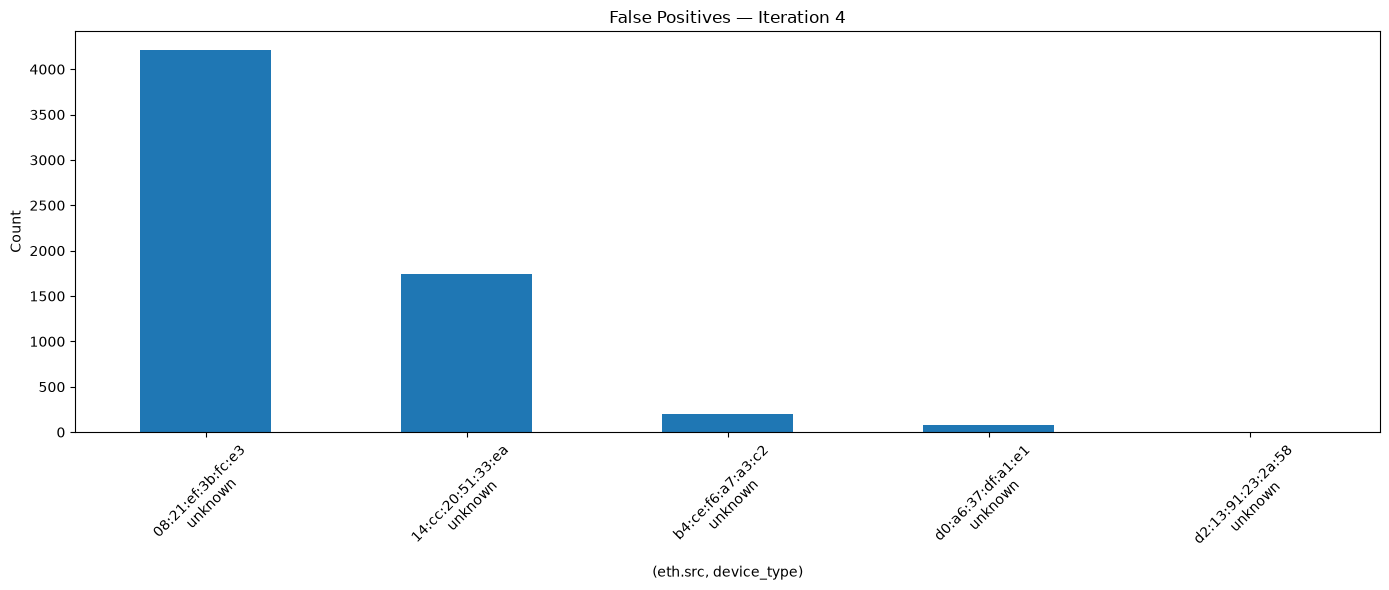

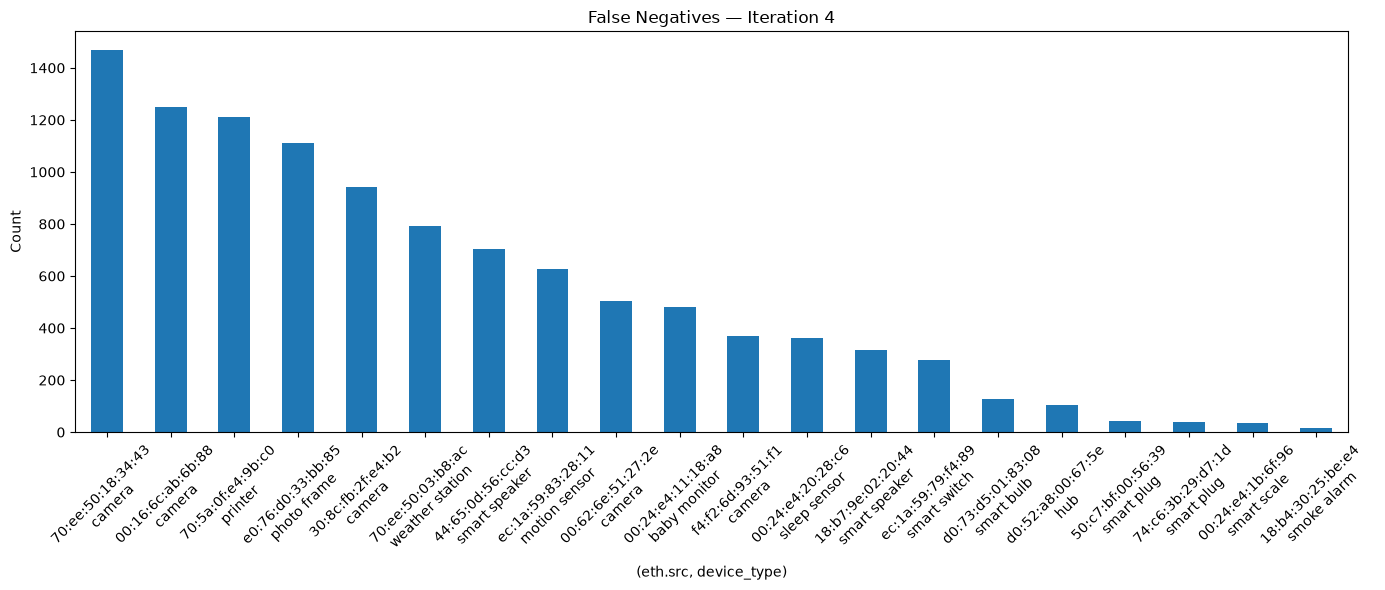

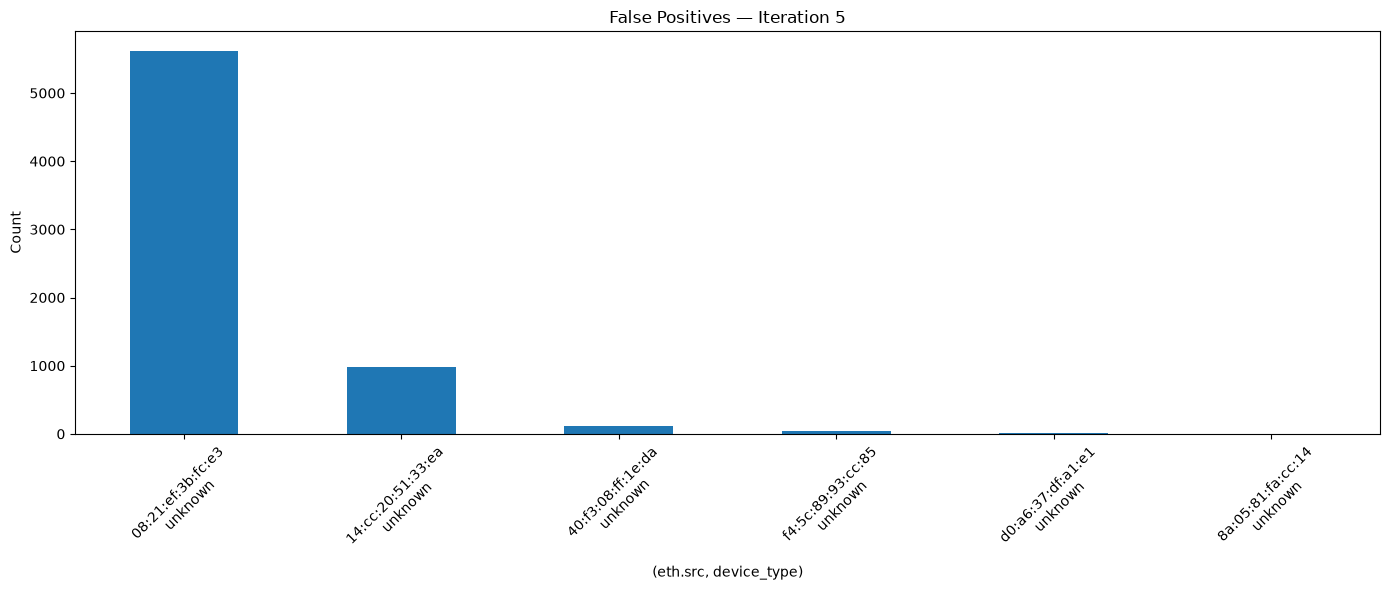

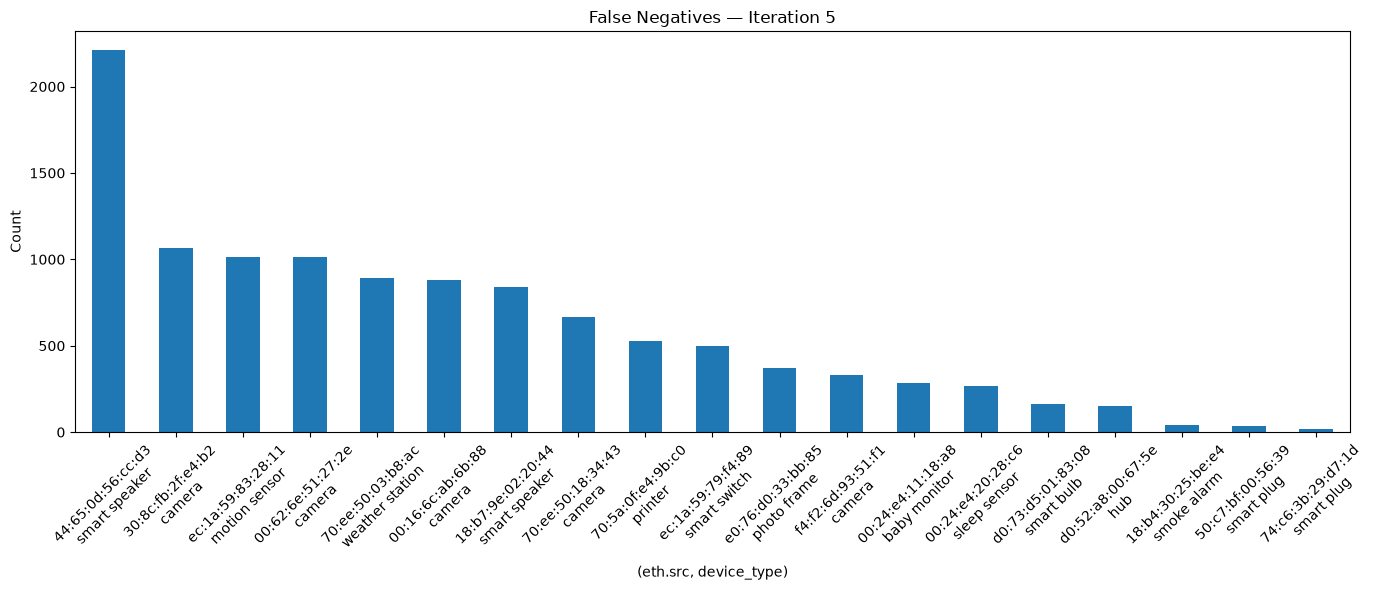

In [24]:
plot_errors_by_iteration(metrics_df)

In [25]:
allFeatures1 = features1.copy()
allFeatures1.head(10)

,window,eth.src,packet_count,total_bytes,timestamp,capture_id,is_iot_device,device_type,vendor
0,0,18:b7:9e:02:20:44,3,202,1.474553e+09,16-09-23,1,smart speaker,Invoxia
1,0,14:cc:20:51:33:ea,18,1449,1.474553e+09,16-09-23,0,unknown,unknown
2,0,d0:52:a8:00:67:5e,3,259,1.474553e+09,16-09-23,1,hub,Samsung SmartThings
3,0,70:ee:50:18:34:43,3,284,1.474553e+09,16-09-23,1,camera,Netatmo
4,0,ec:1a:59:79:f4:89,1,42,1.474553e+09,16-09-23,1,smart switch,Belkin
5,0,30:8c:fb:2f:e4:b2,4,624,1.474553e+09,16-09-23,1,camera,Dropcam
6,0,00:24:e4:11:18:a8,2,132,1.474553e+09,16-09-23,1,baby monitor,Withings
7,1,08:21:ef:3b:fc:e3,2,108,1.474553e+09,16-09-23,0,unknown,unknown
8,1,14:cc:20:51:33:ea,7,495,1.474553e+09,16-09-23,0,unknown,unknown
9,1,f4:f2:6d:93:51:f1,2,214,1.474553e+09,16-09-23,1,camera,TP-Link


In [26]:
allX, allY = allFeatures1[FEATURE_COLUMNS], allFeatures1[LABEL_COLUMN]
sampler = create_under_sampler(random_seed=RANDOM_STATE)
X_resampled, y_resampled = sampler.fit_resample(allX, allY)
scaler = StandardScaler()
X_resampled_scaled = scaler.fit_transform(X_resampled)
model = create_decision_tree(random_seed=RANDOM_STATE)
model.fit(X_resampled_scaled, y_resampled)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

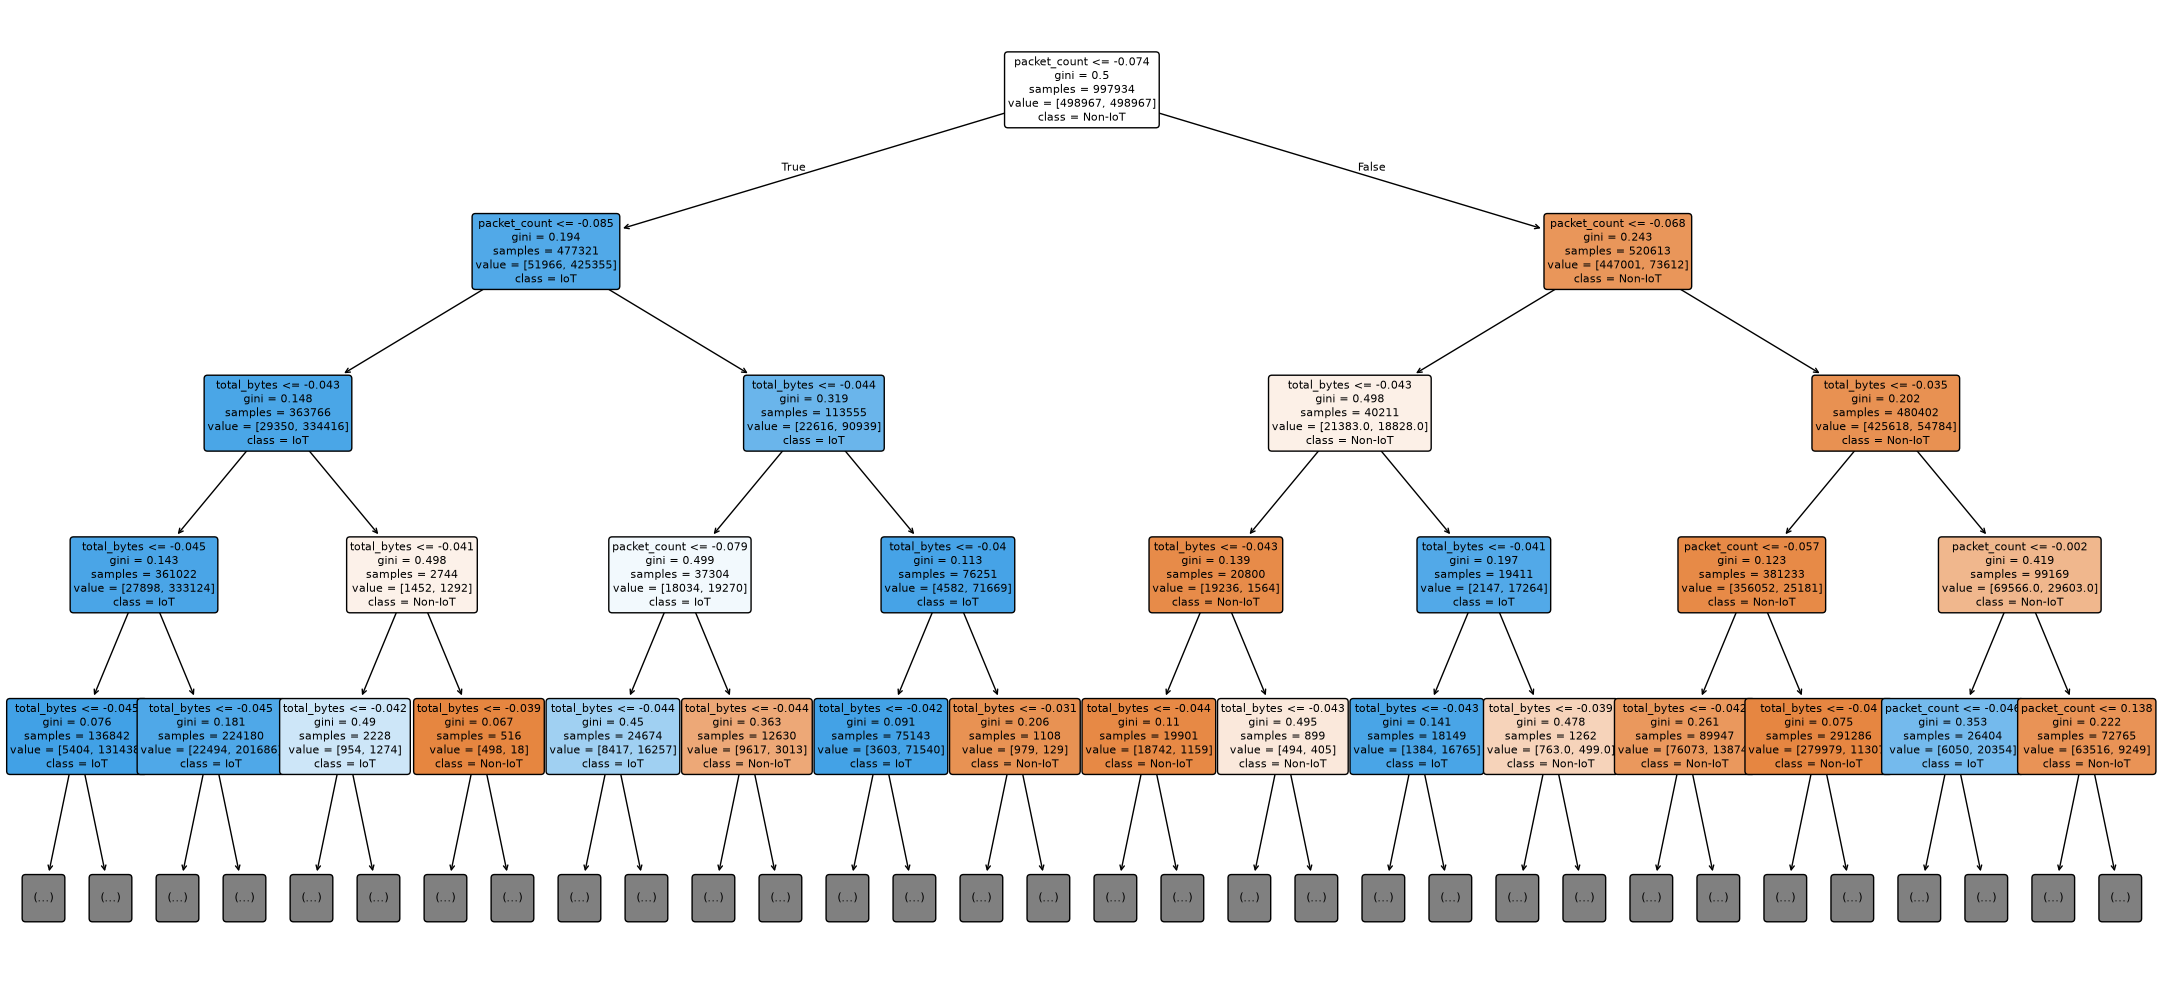

In [27]:
from sklearn.tree import plot_tree
plt.figure(figsize=(22,10))
plot_tree(
    model,
    feature_names=FEATURE_COLUMNS,
    class_names=["Non-IoT", "IoT"],
    filled=True,
    rounded=True,
    max_depth=4,
    fontsize=8,
)

plt.tight_layout()
plt.show()

In [28]:
import joblib

joblib.dump(model, "decision_tree_iot_classifier.pkl")

['decision_tree_iot_classifier.pkl']

In [29]:
csv_files_2 = [f"{INPUT_2}/{f.name}" for f in sorted(Path(INPUT_2).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_2:
    print(file)

../../../dataset/processed-data/input-data/dataset2/arlo-hub-01.csv
../../../dataset/processed-data/input-data/dataset2/august-hub-01.csv
../../../dataset/processed-data/input-data/dataset2/blink-cam-01.csv
../../../dataset/processed-data/input-data/dataset2/blink-cam-02.csv
../../../dataset/processed-data/input-data/dataset2/blink-cam-03.csv
../../../dataset/processed-data/input-data/dataset2/blink-hub-01.csv
../../../dataset/processed-data/input-data/dataset2/geeni-awarecam-1.csv
../../../dataset/processed-data/input-data/dataset2/geeni-awarecam-2.csv
../../../dataset/processed-data/input-data/dataset2/geeni-cam-01.csv
../../../dataset/processed-data/input-data/dataset2/geeni-cam-03.csv
../../../dataset/processed-data/input-data/dataset2/geeni-doorbell-01.csv
../../../dataset/processed-data/input-data/dataset2/geeni-doorbell-02.csv
../../../dataset/processed-data/input-data/dataset2/hub-02.csv
../../../dataset/processed-data/input-data/dataset2/hue-hub-01.csv
../../../dataset/process

In [30]:
device_mapping_2 = pd.read_csv(MAPPING_LIST_2)
device_dict_2 = (
    device_mapping_2
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_2

{'9c:3d:cf:94:aa:c3': {'device_name': 'arlo-hub-01',
  'ip_address': '192.168.1.100',
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Arlo'},
 '18:b4:30:8f:ec:23': {'device_name': 'nest-cam-01',
  'ip_address': '192.168.1.101',
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Nest'},
 '64:16:66:73:e6:e0': {'device_name': 'nest-doorbell-01',
  'ip_address': '192.168.1.102',
  'is_iot_device': 1,
  'device_type': 'video doorbell',
  'vendor': 'Nest'},
 '4c:17:44:a4:0b:30': {'device_name': 'amazon-show-01',
  'ip_address': '192.168.1.104',
  'is_iot_device': 1,
  'device_type': 'smart display',
  'vendor': 'Amazon'},
 '08:84:9d:09:4a:69': {'device_name': 'amazon-dot-01',
  'ip_address': '192.168.1.105',
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 'fc:49:2d:76:33:a5': {'device_name': 'amazon-dot-02',
  'ip_address': '192.168.1.106',
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '58:b3:fc:68:a6:e2'

In [31]:
def create_device_window_features(
    basic_features: pd.DataFrame,
    windows_per_sample: int = 10,
) -> pd.DataFrame:
    required_columns = {
        "capture_id",
        "eth.src",
        "window",
        "packet_count",
        "total_bytes",
        "timestamp",
    }

    missing = required_columns - set(basic_features.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    records: List[dict] = []

    grouped = basic_features.groupby(
        ["capture_id", "eth.src"],
        sort=False,
        observed=True,
    )

    for (capture_id, eth_src), group_df in grouped:
        group_df = (
            group_df
            .sort_values("window")
            .reset_index(drop=True)
        )

        total_windows = len(group_df)

        if total_windows < windows_per_sample:
            continue

        start_positions = list(
            range(
                0,
                total_windows - windows_per_sample + 1,
                windows_per_sample,
            )
        )

        # Reuse previous windows for the final incomplete block.
        final_start = total_windows - windows_per_sample

        if start_positions[-1] != final_start:
            start_positions.append(final_start)

        for sample_number, start in enumerate(start_positions):
            block = group_df.iloc[
                start : start + windows_per_sample
            ]

            features = block[
                ["packet_count", "total_bytes"]
            ].to_numpy(dtype=np.int64)

            timestamps = block[
                "timestamp"
            ].to_numpy(dtype=np.float64)

            records.append(
                {
                    "capture_id": capture_id,
                    "eth.src": eth_src,
                    "sample_number": sample_number,
                    "feature": features,
                    "timestamps": timestamps,
                }
            )

    return pd.DataFrame(records)

In [32]:
def calculate_features_b(
    file_paths: Iterable[str],
    window: float,
) -> Tuple[pd.DataFrame, float]:
    if window <= 0:
        raise ValueError("window must be greater than 0.")

    columns = [
        "frame.time_epoch",
        "frame.len",
        "eth.src",
    ]

    all_features = []
    start_time = time.perf_counter()

    for file_path in file_paths:
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
            },
        )

        if df.empty:
            continue

        capture_start = df["frame.time_epoch"].min()

        df["window"] = (
            (df["frame.time_epoch"] - capture_start) // window
        ).astype("int32")

        basic_features = (
            df.groupby(
                ["window", "eth.src"],
                sort=False,
                observed=True,
            )
            .agg(
                packet_count=("frame.len", "size"),
                total_bytes=("frame.len", "sum"),

                # Timestamp of the first packet from this device
                # within this window.
                timestamp=("frame.time_epoch", "min"),
            )
            .reset_index()
        )

        # Retain which input capture produced each feature row.
        basic_features["capture_id"] = Path(file_path).stem

        aggregated_features = create_device_window_features(
            basic_features,
            windows_per_sample=N_VOTING_WINDOWS,
        )

        all_features.append(aggregated_features)



    elapsed_time = time.perf_counter() - start_time


    result = pd.concat(
        all_features,
        ignore_index=True,
    )


    return result, elapsed_time

In [33]:
allDataB, _ = calculate_features_b(csv_files_2, window=WINDOW_SECONDS)

In [34]:
allDataB.head(10)

,capture_id,eth.src,sample_number,feature,timestamps
0,arlo-hub-01,00:1c:7f:53:d0:28,0,"[[2, 140], [1, 60], [2, 140], [41, 22284], [4,...","[1615213800.183996, 1615213805.213223, 1615213..."
1,arlo-hub-01,00:1c:7f:53:d0:28,1,"[[1, 70], [1, 70], [1, 70], [1, 60], [1, 70], ...","[1615213907.478084, 1615213914.359755, 1615213..."
2,arlo-hub-01,00:1c:7f:53:d0:28,2,"[[1, 70], [1, 70], [1, 70], [2, 130], [1, 70],...","[1615214002.93487, 1615214008.075758, 16152140..."
3,arlo-hub-01,00:1c:7f:53:d0:28,3,"[[2, 140], [1, 60], [2, 140], [2, 140], [1, 60...","[1615214108.418776, 1615214113.446785, 1615214..."
4,arlo-hub-01,00:1c:7f:53:d0:28,4,"[[2, 130], [1, 70], [1, 70], [1, 70], [1, 60],...","[1615214214.219742, 1615214229.397301, 1615214..."
5,arlo-hub-01,00:1c:7f:53:d0:28,5,"[[2, 140], [1, 60], [2, 140], [1, 70], [2, 130...","[1615214328.573235, 1615214333.601041, 1615214..."
6,arlo-hub-01,00:1c:7f:53:d0:28,6,"[[1, 70], [1, 60], [1, 70], [1, 70], [1, 70], ...","[1615214430.584337, 1615214435.527545, 1615214..."
7,arlo-hub-01,00:1c:7f:53:d0:28,7,"[[1, 70], [1, 70], [2, 130], [2, 140], [1, 70]...","[1615214511.056284, 1615214526.743185, 1615214..."
8,arlo-hub-01,00:1c:7f:53:d0:28,8,"[[1, 70], [1, 70], [1, 60], [1, 70], [1, 70], ...","[1615214631.777706, 1615214641.430176, 1615214..."
9,arlo-hub-01,00:1c:7f:53:d0:28,9,"[[160, 11200], [146, 10896], [2, 140], [2, 140...","[1615214716.546205, 1615214720.199985, 1615214..."


In [35]:
labelledDataB = label_features(allDataB, device_dict_2)
labelledDataB.head(10)

,capture_id,eth.src,sample_number,feature,timestamps,is_iot_device,device_type,vendor
0,arlo-hub-01,00:1c:7f:53:d0:28,0,"[[2, 140], [1, 60], [2, 140], [41, 22284], [4,...","[1615213800.183996, 1615213805.213223, 1615213...",0,unknown,unknown
1,arlo-hub-01,00:1c:7f:53:d0:28,1,"[[1, 70], [1, 70], [1, 70], [1, 60], [1, 70], ...","[1615213907.478084, 1615213914.359755, 1615213...",0,unknown,unknown
2,arlo-hub-01,00:1c:7f:53:d0:28,2,"[[1, 70], [1, 70], [1, 70], [2, 130], [1, 70],...","[1615214002.93487, 1615214008.075758, 16152140...",0,unknown,unknown
3,arlo-hub-01,00:1c:7f:53:d0:28,3,"[[2, 140], [1, 60], [2, 140], [2, 140], [1, 60...","[1615214108.418776, 1615214113.446785, 1615214...",0,unknown,unknown
4,arlo-hub-01,00:1c:7f:53:d0:28,4,"[[2, 130], [1, 70], [1, 70], [1, 70], [1, 60],...","[1615214214.219742, 1615214229.397301, 1615214...",0,unknown,unknown
5,arlo-hub-01,00:1c:7f:53:d0:28,5,"[[2, 140], [1, 60], [2, 140], [1, 70], [2, 130...","[1615214328.573235, 1615214333.601041, 1615214...",0,unknown,unknown
6,arlo-hub-01,00:1c:7f:53:d0:28,6,"[[1, 70], [1, 60], [1, 70], [1, 70], [1, 70], ...","[1615214430.584337, 1615214435.527545, 1615214...",0,unknown,unknown
7,arlo-hub-01,00:1c:7f:53:d0:28,7,"[[1, 70], [1, 70], [2, 130], [2, 140], [1, 70]...","[1615214511.056284, 1615214526.743185, 1615214...",0,unknown,unknown
8,arlo-hub-01,00:1c:7f:53:d0:28,8,"[[1, 70], [1, 70], [1, 60], [1, 70], [1, 70], ...","[1615214631.777706, 1615214641.430176, 1615214...",0,unknown,unknown
9,arlo-hub-01,00:1c:7f:53:d0:28,9,"[[160, 11200], [146, 10896], [2, 140], [2, 140...","[1615214716.546205, 1615214720.199985, 1615214...",0,unknown,unknown


In [36]:
labelledDataB["is_iot_device"].value_counts()

is_iot_device
1    204969
0    149583
Name: count, dtype: int64

In [37]:
predictB = labelledDataB.copy()

In [38]:
modelA = joblib.load("decision_tree_iot_classifier.pkl")

In [39]:
def majority_vote_on_predict_label(predictions: np.ndarray) -> np.ndarray:
    # Get the predicted label for each window.
    # Example:
    # [[0.8, 0.2], [0.3, 0.7]] -> [0, 1]
    labels = np.argmax(predictions, axis=1)

    # Count how many windows predict 0 and how many predict 1
    count_0 = np.sum(labels == 0)
    count_1 = np.sum(labels == 1)

    # Return the dominant label, bias toward non IoT (0) in case of a tie
    if count_1 >= count_0:
        return 1
    else:
        return 0

In [40]:
def custom_predict(model, feature, majority_rule):
    X = np.asarray(feature)
    predictions = model.predict_proba(X)
    
    return majority_rule(predictions)

In [41]:
predictB["predicted_label_majority_on_labels"] = predictB["feature"].apply(
    lambda feature: custom_predict(modelA, feature, majority_vote_on_predict_label)
)

In [42]:
y_true = predictB["is_iot_device"]
y_pred = predictB["predicted_label_majority_on_labels"]

In [43]:
metricMajorityOnLabels = custom_evaluation(y_pred, y_true, predictB, np.unique(y_true))
metricMajorityOnLabelsDf = pd.DataFrame([metricMajorityOnLabels])

In [44]:
metricMajorityOnLabelsDf

,accuracy,precision_class_0,recall_class_0,f1_class_0,precision_class_1,recall_class_1,f1_class_1,false_positives,false_negatives
0,0.514382,0.442082,0.576456,0.500405,0.602795,0.469081,0.527598,"{('00:1c:7f:53:d0:28', 'unknown'): 62648, ('cc...","{('00:03:7f:ee:4f:e5', 'hub'): 730, ('0c:8c:24..."


In [45]:
def plot_errors(metric):
    for column, title in [
        ("false_positives", "False Positives"),
        ("false_negatives", "False Negatives"),
    ]:
        error_dict = metric[column]

        plot_df = pd.DataFrame(
            [
                {
                    "category": f"{eth_src}\n{device_type}",
                    "count": count,
                }
                for (eth_src, device_type), count in error_dict.items()
            ]
        ).sort_values("count", ascending=False)

        ax = plot_df.plot(
            x="category",
            y="count",
            kind="bar",
            figsize=(14, 6),
            legend=False,
        )

        ax.set_title(f"{title}")
        ax.set_xlabel("(eth.src, device_type)")
        ax.set_ylabel("Count")
        ax.tick_params(axis="x", rotation=45)

        plt.tight_layout()
        plt.show()

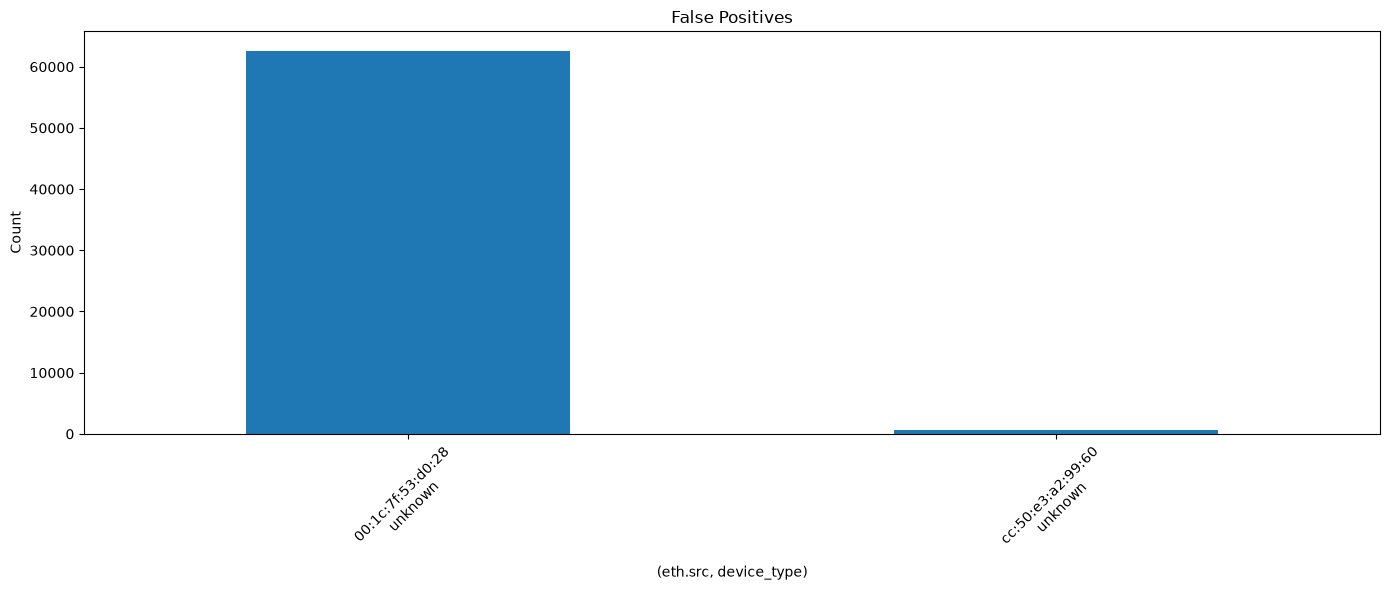

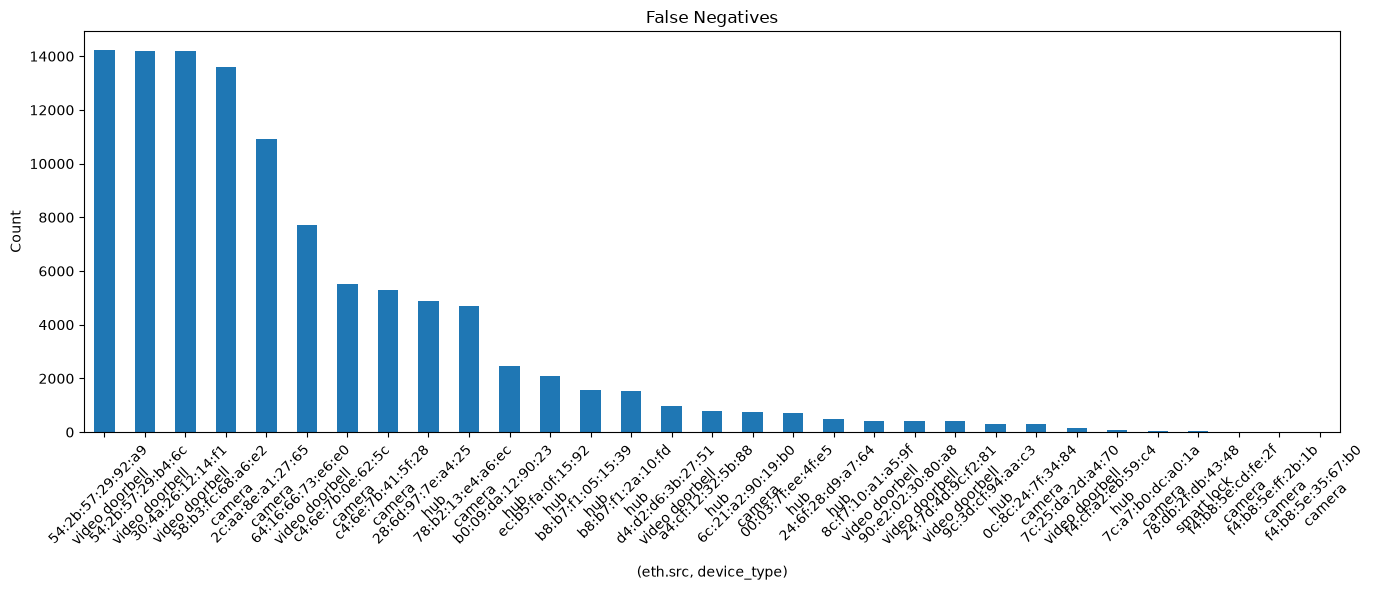

In [46]:
plot_errors(metricMajorityOnLabels)

In [47]:
def average_probability_rule(predictions):
    # predictions[:, 1] = probability of being an IoT device
    iot_probabilities = predictions[:, 1]

    # Average probability across all windows
    average_iot_probability = np.mean(iot_probabilities)

    # Classify based on 0.5 threshold
    if average_iot_probability >= 0.5:
        return 1
    else:
        return 0

In [48]:
predictB["predicted_label_average_probability"] = predictB["feature"].apply(
    lambda feature: custom_predict(modelA, feature, average_probability_rule)
)

In [49]:
metricMajorityOnAverageProbability = custom_evaluation(predictB["predicted_label_average_probability"], predictB["is_iot_device"], predictB, np.unique(y_true))
metricMajorityOnAverageProbabilityDf = pd.DataFrame([metricMajorityOnAverageProbability])
metricMajorityOnAverageProbabilityDf

,accuracy,precision_class_0,recall_class_0,f1_class_0,precision_class_1,recall_class_1,f1_class_1,false_positives,false_negatives
0,0.514382,0.442082,0.576456,0.500405,0.602795,0.469081,0.527598,"{('00:1c:7f:53:d0:28', 'unknown'): 62648, ('cc...","{('00:03:7f:ee:4f:e5', 'hub'): 730, ('0c:8c:24..."


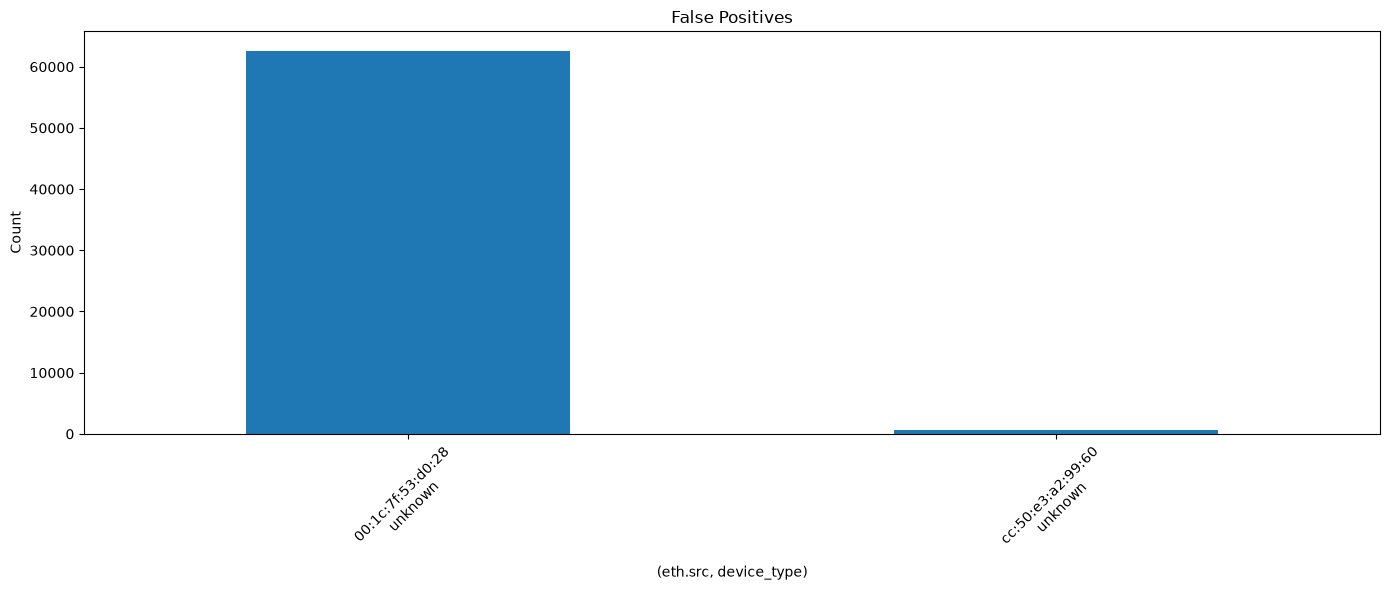

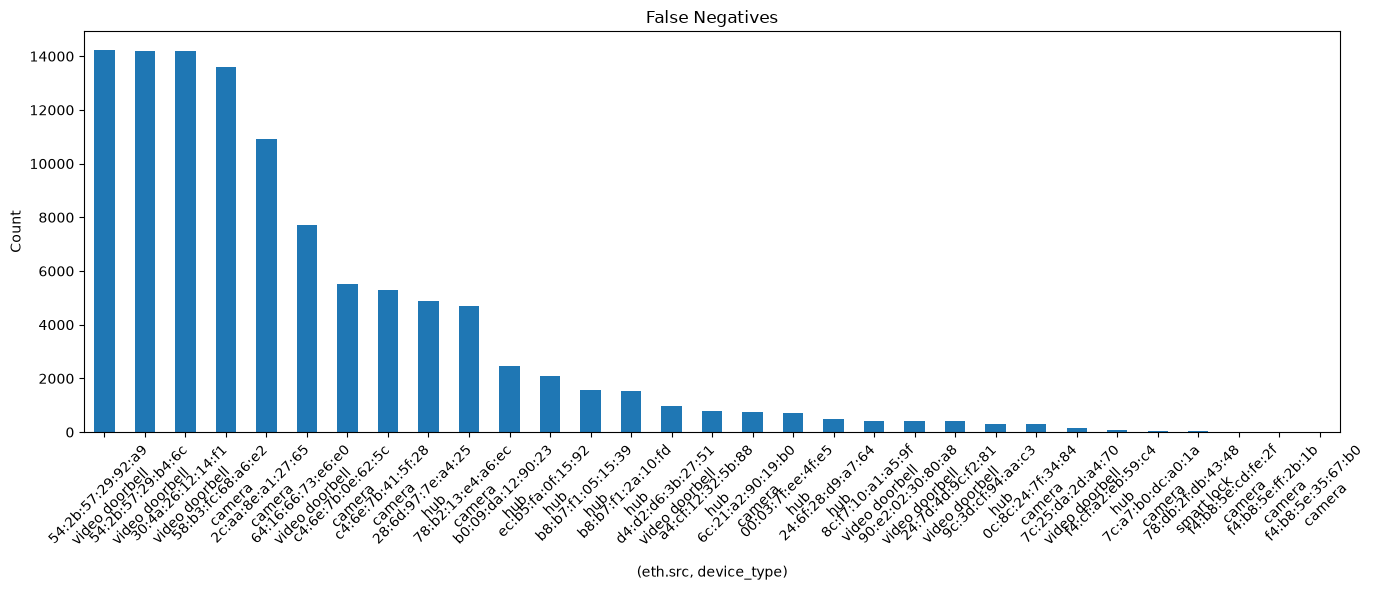

In [50]:
plot_errors(metricMajorityOnLabels)